# Predicting the Quality Factor of Optical Microresonators

## Introduction

This project investigates the use of machine learning
to predict the quality factor (Q-factor) of optical
microresonators.

The objective is to explore the dataset, preprocess
its features, train regression models, and evaluate
their predictive performance.

### Dataset Source

This project uses a synthetic dataset of all-pass optical
micro-ring resonators originally developed by
Valencia-Garzon et al. [1].

The dataset was generated using numerical simulations
to investigate relationships between resonator geometry
and optical performance.

**References**

[1] S. Valencia-Garzon et al.,
"Synthetic Dataset for Analyzing Geometry-Dependent
Optical Properties of All-Pass Micro-Ring Resonators,"
*Data*, vol. 10, no. 1, art. 3, 2025.
https://doi.org/10.3390/data10010003

[2] R. Paschotta, "Q-factor," *RP Photonics Encyclopedia*. Accessed: Nov. 4, 2026. [Online]. Available: https://www.rp-photonics.com/q_factor.html

### Library Imports

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Microresonator ML environment ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Microresonator ML environment ready!
NumPy: 2.4.6
Pandas: 3.1.0
Scikit-learn: 1.9.1


In [21]:
df = pd.read_csv("data/Data set Microresonator Optical.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (4718, 15)


,w [um],h [um],R [um],GAP [um],FSR [nm],FWHM [nm],Q FACTOR,LOSS,FINESSE,k,t,MAX TRANSMITTANCE,MIN TRANSMITTANCE,EFFECTIVE INDEX,% TRANSMITTANCE
0,1.0,0.18,40.0,0.5,6.40935,3.073140,504.708109,0.043525,2.085603,0.741274,0.089850,0.578010,0.519857,1.493476,0.058152
1,1.0,0.18,40.0,0.6,6.40935,3.064473,506.135523,0.043525,2.091502,0.790169,0.054119,0.649596,0.597896,1.493476,0.051700
2,1.0,0.18,40.0,0.7,6.40935,3.059536,506.952297,0.043525,2.094877,0.817994,0.032338,0.692059,0.644906,1.493476,0.047153
3,1.0,0.18,40.0,0.8,6.40935,3.056374,507.476654,0.043525,2.097044,0.835634,0.019320,0.719622,0.675694,1.493476,0.043928
4,1.0,0.18,40.0,0.9,6.40935,3.054563,507.777617,0.043525,2.098287,0.845953,0.011536,0.735977,0.694061,1.493476,0.041916


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4718 entries, 0 to 4717
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   w [um]             4718 non-null   float64
 1   h [um]             4718 non-null   float64
 2   R [um]             4718 non-null   float64
 3   GAP [um]           4718 non-null   float64
 4   FSR [nm]           4718 non-null   float64
 5   FWHM [nm]          4718 non-null   float64
 6   Q FACTOR           4718 non-null   float64
 7   LOSS               4718 non-null   float64
 8   FINESSE            4718 non-null   float64
 9   k                  4718 non-null   float64
 10  t                  4718 non-null   float64
 11  MAX TRANSMITTANCE  4718 non-null   float64
 12  MIN TRANSMITTANCE  4718 non-null   float64
 13  EFFECTIVE INDEX    4718 non-null   float64
 14  % TRANSMITTANCE    4718 non-null   float64
dtypes: float64(15)
memory usage: 553.0 KB


In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
w [um],4718.0,1.295549,0.222788,1.000000,1.000000,1.200000,1.400000,1.600000
h [um],4718.0,0.219407,0.027730,0.180000,0.200000,0.220000,0.240000,0.260000
R [um],4718.0,114.310089,49.557464,30.000000,70.000000,115.000000,155.000000,200.000000
GAP [um],4718.0,0.800000,0.200021,0.500000,0.600000,0.800000,1.000000,1.100000
FSR [nm],4718.0,2.814006,1.671500,1.207710,1.590400,2.187300,3.493490,8.487540
FWHM [nm],4718.0,0.151588,0.375026,0.007265,0.026520,0.051433,0.106436,3.846600
Q FACTOR,4718.0,41943.444701,37750.906094,403.774633,14556.374189,30151.077310,58445.196537,213296.217639
LOSS,4718.0,0.959268,0.124107,0.043525,0.980849,0.994258,0.998058,0.999793
FINESSE,4718.0,60.090317,48.951221,2.085603,22.356736,44.084309,85.659283,227.011466
k,4718.0,0.919736,0.074590,0.376243,0.899523,0.943804,0.968272,0.987431


In [24]:
df.duplicated().sum()

np.int64(0)

### What is Quality Factor?
Quality factor is the ratio between stored energy and energy dissipated per radian of oscillation. It is characterized as the measure of strength of the damping of its oscillations, for example if we have a high Q factor we will receive lower damping and lower energy loss relative to the stored energy. [2]


The quality factor for microring resonators is defined as:

$$
Q = \frac{\lambda_{\mathrm{res}}}{\mathrm{FWHM}}
$$

Rearranging:

$$
\lambda_{\mathrm{res}} = Q \cdot \mathrm{FWHM}
$$

Gives us the resonance wavelength.


Since Q-factor is the target variable, its distribution must be examined to understand its variability and identify the type of skewness

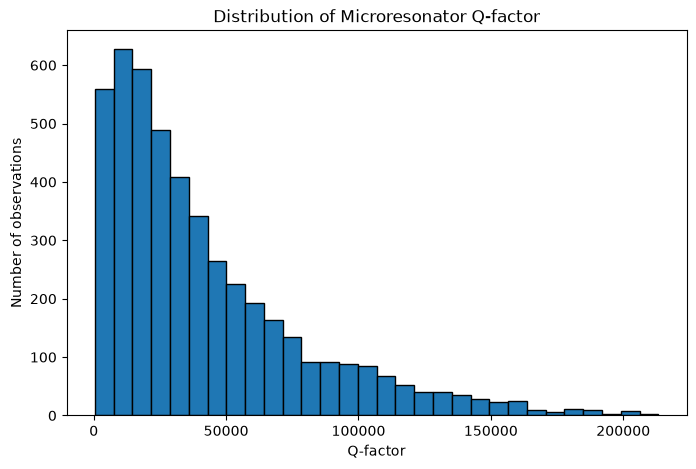

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(df["Q FACTOR"], bins=30, edgecolor="black")

plt.xlabel("Q-factor")
plt.ylabel("Number of observations")
plt.title("Distribution of Microresonator Q-factor")

plt.show()

In [26]:
df["Q FACTOR"].skew()

np.float64(1.468498039876496)

In [27]:
ex = df["Q FACTOR"] > 150000
ex_mean = ex.mean()
print(f"Approximately {ex_mean:.2%} of resonators have Q-factors that exceed 150,000")

Approximately 1.93% of resonators have Q-factors that exceed 150,000


Using the resonance wavelength equation we find:

In [28]:
df.columns = df.columns.str.strip()

(df["Q FACTOR"] * df["FWHM [nm]"]).describe()

count    4718.000000
mean     1549.962056
std         0.907772
min      1546.515800
25%      1549.455680
50%      1549.987340
75%      1550.483560
max      1553.159360
dtype: float64

Although the resonance wavelength is related to the resonator's optical properties, it will not be used as a predictor because this project is focused on the geometry based Q-factor estimation. 

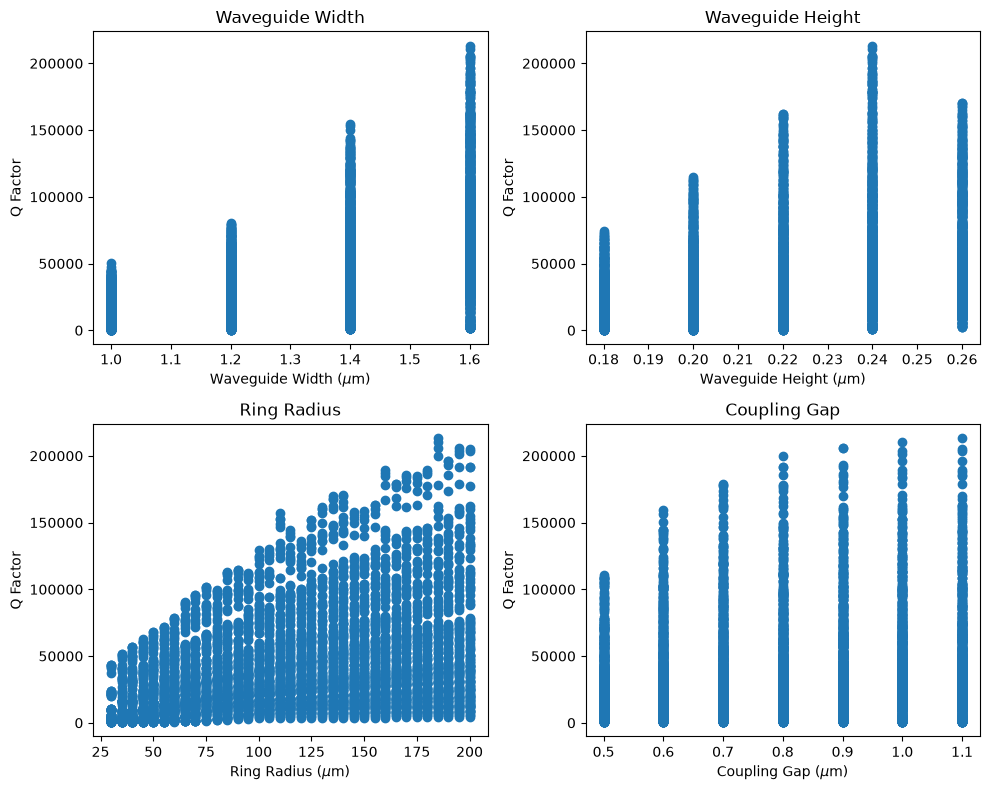

In [41]:
features = {'Waveguide Width' : df['w [um]'], 'Waveguide Height' : df['h [um]'], 'Ring Radius' : df['R [um]'], 'Coupling Gap' : df['GAP [um]']}
target = df['Q FACTOR']
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, column) in zip(axs.flat, features.items()):
    ax.scatter(column, target)
    ax.set_title(name)
    ax.set_xlabel(f"{name} ($\\mu$m)")
    ax.set_ylabel("Q Factor")
fig.tight_layout()
plt.show()

Ring radius appears to have the strongest correlation with Q factor let's explore that below:

In [36]:
radius = df['R [um]']
r_corr = radius.corr(target)
print(f'The correlation between radius and Q Factor is {r_corr:.3f}')

The correlation between radius and Q Factor is 0.382


Waveguide widths and heights had a stronger correlation than the radius, meaning my hypothesis was incorrect. Since the corrwith() method defaults to Pearson correlation which is associated with a linear association, it does not guarantee that a weaker coefficient is irrelevant to predicting the Q Factor.

In [52]:
geometric_df = pd.DataFrame(features)
geometric_df.corrwith(target)

Waveguide Width     0.624294
Waveguide Height    0.407844
Ring Radius         0.382264
Coupling Gap        0.187773
dtype: float64

In [58]:
X = geometric_df
y = df["Q FACTOR"]
X.columns

Index(['Waveguide Width', 'Waveguide Height', 'Ring Radius', 'Coupling Gap'],
      dtype='str')

In [59]:
X.duplicated().sum()

np.int64(0)